In [11]:
from valurap import rest_client
import imp
imp.reload(rest_client)

c = rest_client.Client()
c.abort()
c.home()
c.wait_idle()
c.moveto(X1=0)
c.moveto(Y=0)
c.wait_idle()

{'idle': True,
 'state': {'apg_states': [{'name': 'X1', 'x': -0.41015625, 'v': 0},
   {'name': 'X2', 'x': -13501.1484375, 'v': 0},
   {'name': 'Y', 'x': -0.41015625, 'v': 0}],
  'pc': 31,
  'free_buf': None,
  'code_len': 0,
  'busy': 0},
 'abs_safe': True}

In [6]:
#c.moveto(X1=1000)
#c.moveto(X2=1000)
c.moveto(X1=-2000,X2=-2000)
#c.moveto(Y=-500)
c.wait_idle()

{'idle': True,
 'state': {'apg_states': [{'name': 'X1', 'x': -2000.23828125, 'v': 0},
   {'name': 'X2', 'x': -2000.2421875, 'v': 0},
   {'name': 'Y', 'x': -0.41015625, 'v': 0}],
  'pc': 41,
  'free_buf': None,
  'code_len': 0,
  'busy': 0},
 'abs_safe': True}

<IPython.core.display.Javascript object>


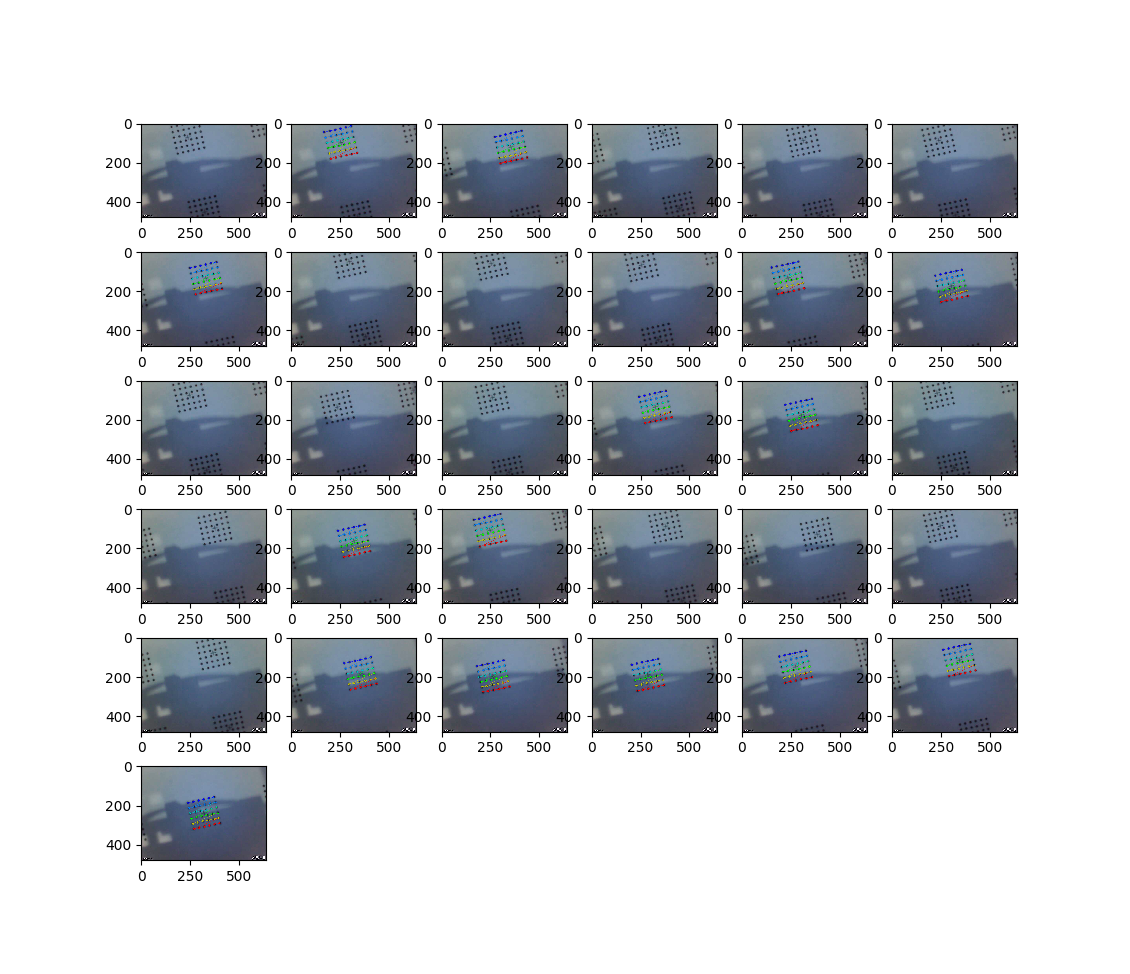

array([[252.63908,  99.27615],
       [349.9862 , 122.98078],
       [329.37878, 133.93393],
       [233.59047, 131.99818],
       [301.42395, 172.38815],
       [321.56808, 132.3841 ],
       [301.60294, 173.29617],
       [320.0897 , 162.59761],
       [243.84825, 107.98308],
       [352.3912 , 181.1927 ],
       [259.93256, 195.72795],
       [283.21768, 188.08064],
       [271.55466, 146.52043],
       [342.3308 , 112.14616]], dtype=float32)

array([[-1086.0078125 , -1571.0078125 ],
       [-1684.03125   , -1286.03125   ],
       [-1536.02734375, -1244.02734375],
       [ -917.01953125, -1386.0234375 ],
       [-1303.0234375 , -1033.01953125],
       [-1488.01953125, -1265.0234375 ],
       [-1302.01171875, -1027.01171875],
       [-1436.0234375 , -1071.0234375 ],
       [-1016.0234375 , -1528.02734375],
       [-1620.0390625 ,  -905.0390625 ],
       [-1000.03125   ,  -944.03515625],
       [-1163.0078125 ,  -962.0078125 ],
       [-1143.015625  , -1245.01171875],
       [-1649.02734375, -1370.02734375]])

array([-6.486042 ,  1.3664883], dtype=float32)

417.57312

array([1.3754249, 6.4351587], dtype=float32)

-2558.8325

-1330.0031261444092

-574.2584686279297

319.74274

239.48248

In [13]:
%matplotlib notebook

import cv2
import math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from random import randint


def get_circles(attempts=4, axe="X1"):
    if axe == "X1":
        cap = cv2.VideoCapture('http://orange:8081/')
    elif axe == "X2":
        cap = cv2.VideoCapture('http://orange:8082/')
    else:
        raise RuntimeError("Unknown axe", axe)
        
    ret, img = cap.read()
    #ret, img = cap.read()
    #ret, img = cap.read()
    cap.release()
    assert img.shape == (480, 640, 3)

    ret, circles = cv2.findCirclesGrid(img, (6,6))
    if ret:
        cv2.drawChessboardCorners(img, (6, 6), circles, ret)
        #display(circles)
        x = circles[:,0][:,0]
        y = circles[:,0][:,1]
        x0 = np.average(x)
        y0 = np.average(y)
        return x0, y0, img
    else:
        if attempts > 0:
            return get_circles(attempts - 1)
    return (None, None, img)

def wait():
    r = c.wait_idle()
    x = None
    y = None
    for s in r["state"]["apg_states"]:
        if s["name"] == "X1":
            x = s["x"]
        if s["name"] == "Y":
            y = s["x"]
            
    return x,y

fig=plt.figure(figsize=(8, 8))
rows = 6
columns = 6

c.moveto(Z=100000)
c.moveto(X2=0)
x0 = 6360 - 32.3*80*3
y0 = 7295 - 33*80*3

a = []
b = []
for i in range(30):
    x1 = x0 + randint(-500, 500)
    y1 = x0 + randint(-500, 500)

    c.moveto(X1=x1, Y=y1)
    r = wait()

    cx, cy, img = get_circles()
    if cx is not None:
        a.append([cx, cy])
        b.append(r)

    fig.add_subplot(rows, columns, i+1)    
    plt.imshow(img)

a = np.array(a)
b = np.array(b)
display(a)
display(b)

x = b[:,0]
y = b[:,1]

reg_x = LinearRegression().fit(a, x)
reg_y = LinearRegression().fit(a, y)
display(reg_x.coef_)
display(reg_x.intercept_)
display(reg_y.coef_)
display(reg_y.intercept_)
tx = reg_x.predict([[320, 240]])[0]
ty = reg_y.predict([[320, 240]])[0]
display(tx, ty)

c.moveto(X1=int(round(tx)),Y=int(round(ty)))
rf = wait()
xf, yf, img = get_circles()
display(xf, yf)
fig.add_subplot(rows, columns, i+2)    
plt.imshow(img)


In [67]:
from sklearn.linear_model import LinearRegression

x = b[:,0]
y = b[:,1]
display(x)
display(y)
display(a)

reg_x = LinearRegression().fit(a, x)
reg_y = LinearRegression().fit(a, y)
display(reg_x.coef_)
display(reg_x.score(a, x))
display(reg_y.coef_)
display(reg_y.score(a, y))
display(reg_x.predict([[320, 240]]))
display(reg_y.predict([[320, 240]]))


array([1261.98828125, 1511.9765625 , 1011.94921875, 1011.94921875,
       1511.921875  ])

array([-546.015625  , -296.02734375, -296.02734375, -796.0546875 ,
       -796.0546875 ])

array([[319.94113, 239.57259],
       [290.88898, 284.0833 ],
       [364.6492 , 268.6214 ],
       [349.33258, 195.3034 ],
       [275.2837 , 210.9223 ]], dtype=float32)

array([-6.477822 ,  1.3678502], dtype=float32)

0.9999949759859988

array([1.374593, 6.537078], dtype=float32)

0.999994953925968

array([1262.49043465])

array([-544.10482788])

In [91]:
dx = (6360 + 11739)/7/80
dy = (7295 + 5922)/5/80
display(dx, dy)

# 0,0 140000
-8.456866 ,  1.7913051, -9416.841
1.7894423, 8.533159, -8356.461

# 0,0 120000
array([-7.446139 ,  1.5698063], dtype=float32)
-9705.434
array([1.583806, 7.500653], dtype=float32)
-8139.1807

# 0,0 100000
array([-6.4907417,  1.3642491], dtype=float32)
383.14453
array([1.3718139, 6.5110373], dtype=float32)
-2597.218

32.31964285714285

33.042500000000004

In [10]:
c.abort()